<a href="https://colab.research.google.com/github/ortizo-117/BMEG_591Q_group_project/blob/master/Lab_A_pt11_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BMEG 400Q-591Q : Lab A


Mounting Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



The dataset is available at the following link: [Dataset Link](https://drive.google.com/drive/folders/11PWCJwV6lK-jV1HPIVWhizc5fmVkVhIr?usp=sharing).
you can create a shortcut in your Google Drive, then you can find it in '/content/drive/MyDrive/'.

In [ ]:
#[TO-DO] Write the path to your data below.
data_path = '/content/drive/MyDrive/BMEG591Q-Data'

In [ ]:
!pip install nilearn

In [ ]:
import os
import imageio
import matplotlib.pyplot as plt
import numpy as np

import nibabel as nib
from PIL import Image, ImageDraw
from scipy.spatial import ConvexHull
from skimage import measure
from matplotlib.animation import FuncAnimation
import cv2
import matplotlib.pyplot as plt
import re
from nilearn import plotting, image

%matplotlib inline

----
## **Part A: Segmentation with X-ray and CT Scans**

In this part of the assignment, you will explore the differences between using **X-ray** and **CT scans** for lung segmentation by applying **thresholding** technique.


---
##### Why is Lung Segmentation Important?

In medical imaging, **segmentation** is a crucial preprocessing step that involves identifying and isolating regions of interest (ROIs) within images. In the context of **lung imaging**, segmentation plays a vital role for several reasons:

1. **Disease Detection and Diagnosis**:  
   - Helps detect abnormalities such as **tumors**, **nodules**, and **lung infections** (e.g., COVID-19 or pneumonia).
   - Differentiates between healthy and affected lung regions, aiding in early diagnosis.

2. **Treatment Planning and Monitoring**:  
   - Lung segmentation provides accurate volume measurements, which are essential for **monitoring disease progression** or **treatment response** (e.g., tumor shrinkage during therapy).

3. **Quantitative Analysis**:  
   - Enables automatic calculation of lung metrics, such as **volume**, **air trapping**, and **lesion load**, which are crucial in respiratory diseases like **chronic obstructive pulmonary disease (COPD)**.

4. **Radiotherapy and Surgery Planning**:  
   - Lung segmentation ensures that only diseased areas are targeted, minimizing damage to healthy lung tissue.

---

### **Segmenting the Lung from an X-ray scan**



(1024, 1024)
uint8


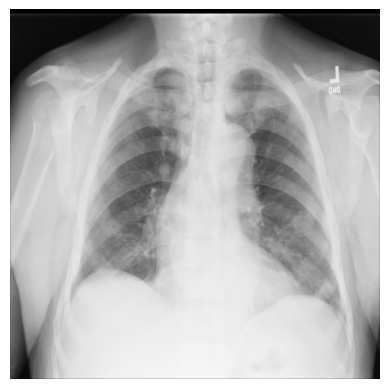

In [ ]:
xray_image = imageio.v3.imread(os.path.join(data_path, "Xray/00000011_001.png"))
print(xray_image.shape)
print(xray_image.dtype)

#Visualize an x-ray image
plt.imshow(xray_image, cmap="gray")
plt.axis("off")
plt.show()


(1024, 1024)
uint8


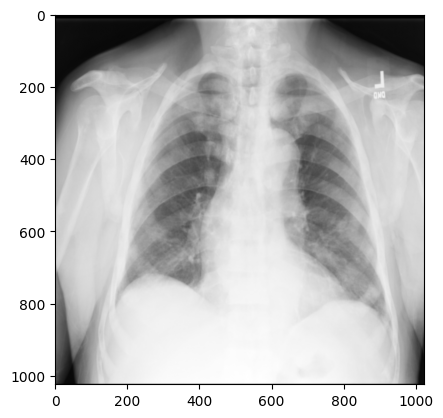

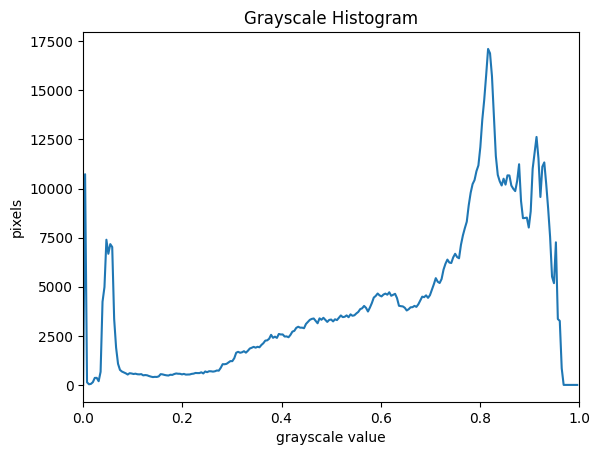

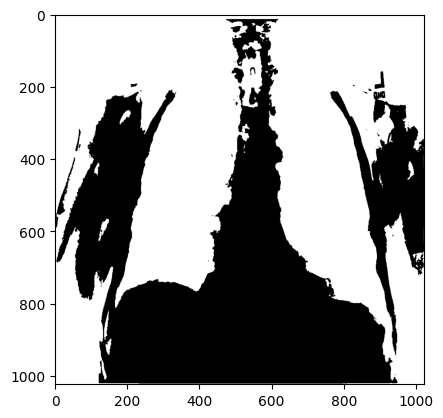

In [ ]:
#TO-DO: Write a Python code to segment an X-ray image using a threshold and
#       visualize the resulting segmentation mask.
xray_image = imageio.v3.imread(os.path.join(data_path, "Xray/00000011_001.png"))
print(xray_image.shape)
print(xray_image.dtype)

import skimage as ski

blurred_shapes = ski.filters.gaussian(xray_image, sigma=1.0)
fig, ax = plt.subplots()
ax.imshow(blurred_shapes, cmap="gray")
# create a histogram of the blurred grayscale image
histogram, bin_edges = np.histogram(blurred_shapes, bins=256, range=(0.0, 1.0))

fig, ax = plt.subplots()
ax.plot(bin_edges[0:-1], histogram)
ax.set_title("Grayscale Histogram")
ax.set_xlabel("grayscale value")
ax.set_ylabel("pixels")
ax.set_xlim(0, 1.0)

# create a mask based on the threshold
t = 0.8
binary_mask = blurred_shapes < t

fig, ax = plt.subplots()
ax.imshow(binary_mask, cmap="gray")

# https://datacarpentry.github.io/image-processing/07-thresholding.html
#Visualize an x-ray image
# plt.imshow(xray_image, cmap="gray")
# plt.axis("off")
# plt.show()



---
#### Discussion
Q1. Why are intensity thresholds used in medical imaging analysis? <br> <br>
<font color="#008000">Answer :</font> Because in most medical imaging modalities, different tissues have different properties that absorb/reflect the signal sent from the emitter (in this case x-rays) and get recorded at different intensities in the reciever/sensor. Through thresholding, we are able to segment different tissues based on their properties (ie. bones reflect more signals in x ray modalities)


Q2. Differences in x-ray intensities are attributable to which physical properties of anatomy? <br> <br>
<font color="#008000">Answer :</font>Differences in x-ray are attributable to the physical density of the tissue as well as the atomic number. The higher atomic number leads to a lower number of photons transmitted through a material.


Q3. Can you think of a relevant clinical application where this filtering technique might be useful? <br> <br>
<font color="#008000">Answer :</font> When detecting cancer of the lungs or in situations where the lung can collapse.


***

### **Segmenting the Lung from a CT scan**


In [ ]:
#TO-DO: Write the following function
def read_nfti(file_path):

    # Load the NIFTI file
    try:
        nifti_image = nib.load(file_path)
        nifti_data = nifti_image.get_fdata()  # Get the image data as a NumPy array
        affine = nifti_image.affine  # Get the affine transformation matrix
        header = nifti_image.header  # Get the NIfTI header
        return nifti_image, nifti_data, header, affine
    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
        return None, None, None
    except Exception as e:
        print(f"An error occurred while reading the NIfTI file: {e}")
        return None, None, None
    # Get the data from the NIFTI file

    return nifti_image,nifti_data, affine



In [ ]:
ct_img, ct_numpy, header, affine = read_nfti(os.path.join(data_path,"CT/coronacases_org_001.nii"))

Visualizing the 3D volume using [Nilearn](https://nilearn.github.io/stable/modules/generated/nilearn.plotting.view_img.html)

In [ ]:
plotting.view_img(ct_img, bg_img=ct_img,cmap='gray')

/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:820: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/tmp/ipython-input-3142170801.py:1: UserWarning: Casting data from int32 to float32
  plotting.view_img(ct_img, bg_img=ct_img,cmap='gray')


---

---
#### Discussion
<br> **Q1: What is the shape of the data in this NIfTI file? What does each dimension represent?** <br><br>
<font color="#008000">Answer:</font>  the shape of the ct_img represents the dimensions of the CT scan in a 3D volumne. Each dimension corresponds to a dimension. X is the sagittal plane, y is the coronal plane and z is the transverse plane.

In [ ]:
ct_img.shape


<br> **Q2: Find the pixel dimensions in the NIfTI header. What are they, and what do they mean?** <br><br>
<font color="#008000">Answer:</font>  The pixel dimensions are -1, 0.810547, 0.810547. They reflect the column, row, and slice spacing respectively.


In [ ]:
print(header)

<br> **Q3: Find the affine value. What is the affine?** <br><br>
<font color="#008000">Answer:</font>  the dimension of a vector space of its translations.

In [ ]:
print(affine)

---

### Visualizations
Animation of 3D Volume Slices

In [ ]:
def plot_ct_animation(ct_numpy, interval=100):


    """Plots the CT scan slices as an animation."""
    num_slices = ct_numpy.shape[2]  # Z-axis slices

    # Initialize the plot
    fig, ax = plt.subplots()
    img = ax.imshow(ct_numpy[:, :, 0], cmap='gray', vmin=np.min(ct_numpy), vmax=np.max(ct_numpy))
    ax.axis('off')  # Hide axes for better visualization

    def update(frame):
        """Updates the image to the current frame."""
        img.set_data(ct_numpy[:, :, frame])
        ax.set_title(f"Slice {frame + 1}/{num_slices}")
        return img,

    # Create animation and loop back to start after last frame
    ani = FuncAnimation(fig, update, frames=num_slices, interval=interval, blit=True, repeat=True)

    # Display the animation in Jupyter Notebook
    from IPython.display import HTML
    plt.close(fig)  # Close the static figure to avoid double display
    return HTML(ani.to_jshtml())


In [ ]:
ct_numpy_rot90 = np.rot90(ct_numpy, 1)

In [ ]:
plot_ct_animation(ct_numpy_rot90)

Comparing against "ground truth"

In [ ]:
#Load the Ground Truth Lung Mask 'coronacases_001.nii'
ct_img_mask, ct_numpy_mask, header, affine = read_nfti(os.path.join(data_path,"CT/coronacases_001.nii"))

In [ ]:
#TO-DO: Rotate the mask for easier visualization
ct_numpy_mask_rot90 = np.rot90(ct_numpy_mask, 1)


In [ ]:
plot_ct_animation(ct_numpy_mask_rot90)

For Simplicity, we will slice the volume and work with a 2D Slice only.

In [ ]:
#TO-DO: Change the 150 to choose any slice
ct_numpy_rot90_slice = ct_numpy_rot90[:,:,150]
ct_numpy_mask_rot90_slice = ct_numpy_mask_rot90[:,:,150]



In [ ]:
def overlay_mask(ct_numpy_slice, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on the CT scan image with a specified color.

    Parameters:
    - ct_numpy_slice: 2D numpy array representing the grayscale CT scan.
    - mask: 2D numpy array representing the binary mask (same shape as ct_numpy).
    - color: Tuple of 3 floats (R, G, B) representing the color to use for the mask (default is red).
    - alpha: float, transparency factor for the overlay (default 0.4).

    Returns:
    - overlay_image: 3D numpy array representing the image with the mask overlaid in the specified color.
    """
    #TO-DO: Normalize CT image to [0, 1] range if it's not already
    ct_normalized = (ct_numpy_slice - np.min(ct_numpy_slice)) / (np.max(ct_numpy_slice) - np.min(ct_numpy_slice))

    # Create an RGB version of the CT scan
    ct_rgb = np.stack([ct_normalized] * 3, axis=-1)  # Convert grayscale to RGB

    # Create an RGB mask in the specified color
    mask_rgb = np.zeros_like(ct_rgb)
    for i in range(3):  # Apply the color to the mask
        mask_rgb[:, :, i] = mask * color[i]

    # Overlay the mask on the CT scan
    overlay_image = (1 - alpha) * ct_rgb + alpha * mask_rgb
    plt.figure()
    plt.imshow(overlay_image, cmap="gray")
    plt.axis('off')


In [ ]:
#Overlay a segmentation mask on the original image
overlay_mask(ct_numpy_rot90_slice, ct_numpy_mask_rot90_slice)

---

### **Understanding CT Windowing and Hounsfield Units (HU)**

In **Computed Tomography (CT)** imaging, different tissues are visualized based on their **Hounsfield Units (HU)**, which represent the tissue's density relative to water. This scale helps differentiate between various body tissues in CT images, with air, fat, water, soft tissues, and bones all having distinct HU values. However, to display this range effectively, we use a technique called **windowing**.

---

 **What are Hounsfield Units (HU)?**

Hounsfield Units are a quantitative scale for describing radiodensity:

- **Air:** -1000 HU (black)  
- **Lungs:** Around -500 HU  
- **Fat:** Between -200 and -100 HU  
- **Water:** 0 HU (reference point)  
- **Soft Tissue:** 30 to 45 HU  
- **Bone:** > 500 HU  
- **Cortical Bone:** Around 1000 HU (white)

The range from -1000 to 1000 HU represents the radiodensity spectrum that a CT scanner can detect.

---

#### **The Concept of CT Windowing**

CT images have a large range of Hounsfield Unit values. However, a computer display is limited in the range of intensities it can show. If all the HU values are mapped directly to grayscale, subtle differences in tissues could be lost. To address this, **windowing** is applied to focus on a specific range of HU values that are most relevant for diagnosis.

---

#### **Window Width (W) and Window Level (L)**

- **Window Width (W):**  
  This is the range of Hounsfield Units that will be mapped to grayscale values.  
  - A **narrow window width** (e.g., 50 HU) highlights subtle differences, such as soft tissues.
  - A **wide window width** (e.g., 500 HU) includes a larger range, suitable for bone imaging.

- **Window Level (L):**  
  This is the midpoint of the window width, centered on a specific HU value.  
  - **Setting the window level around 0 HU** focuses on water and soft tissues.
  - **Higher window levels** (e.g., 300 HU) are better for bone or calcified tissues.
  - **Lower window levels** (e.g., -500 HU) highlight air-filled structures like the lungs.

---

#### **Why Windowing is Important?**

- **Soft Tissue Window** (W = 300, L = 50): Enhances visibility of organs like the liver or brain.
- **Lung Window** (W = 1500, L = -500): Optimizes visualization of lung structures and air-filled spaces.
- **Bone Window** (W = 2000, L = 500): Makes bones and calcified regions more distinct.

---



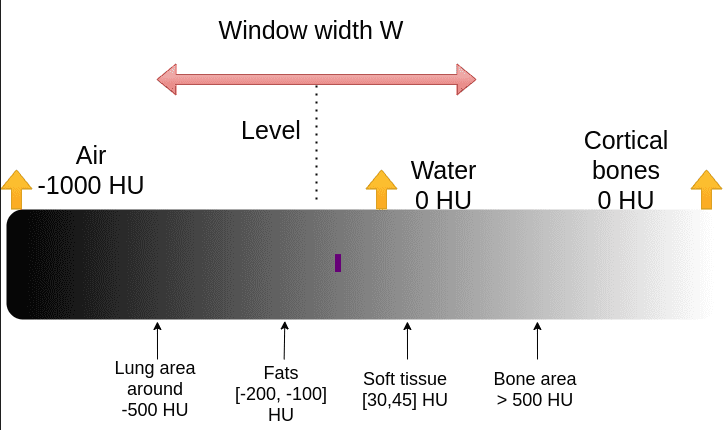

In [ ]:
def show_slice(slice):
    """
    Function to display an image slice
    Input is a numpy 2D array
    """
    plt.figure()
    plt.imshow(slice, cmap="gray")
    plt.axis('off')

In [ ]:
# function to apply windowing on a CT slice.
#       hint: you can use np.clip

def apply_windowing(ct_numpy_rot90_slice, window_center, window_width):

  lower_bound = window_center - window_width/2
  upper_bound = window_center + window_width/2

  ct_numpy_rot90_slice = np.clip(ct_numpy_rot90_slice, lower_bound, upper_bound)

  return ct_numpy_rot90_slice



In [ ]:
#TO-DO: Visualize Original Image

show_slice(ct_numpy_rot90_slice)


In [ ]:
#TO-DO: Visualize a different window of the image.

show_slice(apply_windowing(ct_numpy_rot90_slice, -500, 1500))


---
#### Discussion
<br> Q4: What are two examples of different windows used in clinical application? For each, explain how the window range relates to physical properties of anatomy.<br><br>
<font color="#008000">Answer:</font>  Example 1: Lung contrast - center = -500 and window width = 1500. This optimizes the contrast of the lung structures and air-filled spaces. Because the reference point of a CT is the density of water (0HU), and air has a lower density than water (-1000 HU) by setting the window to a lower HU value we can highlight air-filled structures like the lungs.

Exmple 2 - Bone contrast - center = 500, width = 2000. This optimizes the contrast of bones, as these have a higher relative density compared to water. Setting a higher center is better for contrasting bones or calcified tissues.


### Lung Segmentation from CT Images - Explanation of the Logic

The lung segmentation task involves several stages, each building upon the previous to create a full pipeline for identifying and isolating lung regions from CT images. Below is a detailed explanation of the workflow:





## 3. Contour Filtering  
- To ensure that only relevant contours are considered, we check if each contour is "closed." A closed contour means the boundary forms a loop, which is a characteristic of the lung region.
- This step also filters out small or irrelevant contours based on their volume, ensuring that only significant regions are retained.

## 4. Lung Identification  
- Among the filtered contours, we identify those corresponding to the lungs.
- This involves excluding the body contour (the largest contour) and retaining the next largest two contours, which typically represent the left and right lungs.

## 5. Visualization of Contours  
- The identified lung contours are overlaid on the original CT image to visually confirm their accuracy.
- This step helps in understanding how well the segmentation process has isolated the lungs.

## 6. Binary Mask Creation  
- Using the identified lung contours, we create a binary mask.
- The mask is a black-and-white image where white regions represent the lungs, and black regions represent everything else.



## 7. Integration into a Full Pipeline  
- Finally, all the above steps are combined into a single workflow:
  - Load a CT image.
  - Perform intensity-based segmentation.
  - Detect and filter contours.
  - Identify lung regions.
---



#### 1. Intensity-Based Segmentation  
- First, we focus on segmenting the CT image based on intensity values that correspond to the lung region.
- The process involves clipping the image values to a specific range (`min_val` and `max_val`) to isolate regions of interest.
- The clipped image is then converted into a binary image, where pixel values are either 0 or 1, based on their intensity.

In [ ]:
#TO-DO: Write a Python function to perform Hounsfield unit (HU)
#       window clipping on a CT image, then find the contours
#       within the clipped image
#Hint: You can use skimage.measure


def intensity_seg(ct_numpy, min_val, max_val):
    """
    Segments the CT image by intensity values within a specified range.

    The function clips the CT scan to the given min and max intensity values, then converts
    the intensity values to binary. Any intensity value in range is set to 1, and
    values outside range are set to 0.

    Parameters:
    ----------
    ct_numpy : numpy array
        The CT scan in a 2D numpy array.

    min_val : float
        The minimum intensity value for clipping.

    max_val : float
        The maximum intensity value for clipping.

    Returns:
    -------
    clipped_ct_seg: list of numpy arrays
        The contours found in the binary segmented image.
    contours: numpy array
        The contours found in the binary segmented image.
    """

    ct_numpy_clipped = np.clip(ct_numpy, min_val, max_val)



     # Create a boolean mask where values within the range are True
    #in_range_mask = (ct_numpy >= min_val) & (ct_numpy <= max_val)

    # Convert the boolean mask to an integer array (True becomes 1, False becomes 0)
    clipped_ct_seg = ct_numpy_clipped.astype(int)

    in_range_mask = (ct_numpy >= min_val) & (ct_numpy <= max_val)
    binary_mask = in_range_mask.astype(np.uint8)


    # countour detection
    # 2. Convert the mask to 0 and 255 for OpenCV
    mask_255 = binary_mask  * 255 # need to change the binary into 255 grayscale as per documentatino requirements
    mask_255 = mask_255.astype(np.uint8)
    contours, hierarchy = cv2.findContours(mask_255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)



    return clipped_ct_seg, contours


In [ ]:
help(cv2.RETR_EXTERNAL)

In [ ]:
#TO-DO: Show clipped seg overlaid on image
clipped_ct_seg, contours = intensity_seg(ct_numpy_rot90_slice, -1000, 400)

print(contours)
#overlay_mask(ct_numpy_rot90_slice, clipped_ct_seg)

#### 2. Contour Detection & Filtering
Contours are essential for identifying specific structures, such as the lungs, based on their shape and size.
- Using the binary image, we detect contours, which represent the boundaries of segmented regions.
- To ensure that only relevant contours are considered, we check if each contour is "closed." A closed contour means the boundary forms a loop, which is a characteristic of the lung region.


In [ ]:
def set_is_closed(contour):
    """
    Checks if a contour is closed by calculating the distance between
    the first and last points of the contour.

    Parameters:
    ----------
    contour : numpy array
        A set of points representing the contour.

    Returns:
    -------
    bool
        True if the contour is closed (distance < 1), False otherwise.
    """
    # Calculate the Euclidean distance between the first and last points
    pts = contour.reshape(-1, 2)  # ensure shape (N, 2)
    distance = np.linalg.norm(pts[0] - pts[-1])

    # Check if the distance is less than 1
    contour_bool = distance < 1

    return contour_bool

In [ ]:
for contour in contours:
  print(set_is_closed(contour))


#### 3. Lung Identification  
- Among the filtered contours, we identify those corresponding to the lungs.
- This involves excluding the body contour (the largest contour) and retaining the next largest two contours, which typically represent the left and right lungs.

Note: This step also filters out small or irrelevant contours based on their volume, ensuring that only significant regions are retained.

In [ ]:
def find_lungs(contours):
    """
    Identifies the contours that correspond to the lungs from a set of contours.

    This function excludes open contours and small contours by checking
    1) if they are closed and
    2) if their volume exceeds a threshold.
    The body contour, which has the highest volume, is excluded.
    The remaining contours correspond to the lungs.

    Parameters:
    ----------
    contours : list of numpy arrays
        A list of all detected contours.

    Returns:
    -------
    list of numpy arrays
        The contours corresponding to the lung area.
    """
    body_and_lung_contours = []
    vol_contours = []

    #TO-DO: WRITE THIS FUNCTION
    #Hint: consider using ConvexHull


    for contour in contours:
      if set_is_closed(contour): # check if the contour is closed, if not do somehting else
        # calcuclate the volume of each contour
        vol_contours.append(ConvexHull(contour).volume)
        body_and_lung_contours.append(contour)


    # first zip you contours and vol list into a tupple
    comb_cont_vols = zip(body_and_lung_contours,vol_contours)
    # sort the zipped list by the second element in descending order
    comb_cont_vols_sort = sorted(comb_cont_vols, key=lambda x: x[1], reverse=True)

    # then just subset into the second and third element (lungs only even though the variable says to return body and lung contour?)
    body_and_lung_contours = comb_cont_vols[1:3]

    return body_and_lung_contours


In [ ]:
for contour in contours:
  if set_is_closed(contour): # check if the contour is closed, if not do somehting else
    # calcuclate the volume of each contour
    print(ConvexHull(contour).volume)


#### 4. Visualization of Contours  
- The identified lung contours are overlaid on the original CT image to visually confirm their accuracy.
- This step helps in understanding how well the segmentation process has isolated the lungs.

In [ ]:
def show_contour(image, contours, name=None, save=False):
    """
    Displays the image with overlaid contours. Optionally saves the result to a file.

    Parameters:
    ----------
    image : numpy array
        The image to display.

    contours : list of numpy arrays
        A list of contours to overlay on the image.

    name : str, optional
        The name to save the image (if save=True).

    save : bool, optional
        Whether to save the image to a file (default is False).
    """
    fig, ax = plt.subplots()
    ax.imshow(image, cmap=plt.cm.gray)
    for contour in contours:
        ax.plot(contour[:, 1], contour[:, 0], linewidth=1,color ='red')

    ax.set_xticks([])
    ax.set_yticks([])

    if save:
        plt.savefig(name)
        plt.close(fig)
    else:
        plt.show()

In [ ]:
#TO-DO: show ALL contours overlaid on image
lungs = find_lungs(contours)
show_contour(ct_numpy_rot90_slice, contours, name=None, save=False)


In [ ]:
#TO-DO: show LUNG contours overlaid on image

#### 5. Binary Mask Creation  
- Using the identified lung contours, we create a binary mask.
- The mask is a black-and-white image where white regions represent the lungs, and black regions represent everything else.

In [ ]:
def create_mask_from_contours(ct_numpy_slice, contours):
    """
    Creates a binary mask from polygon contours overlaid on an image.

    The function converts a list of polygon contours into binary masks and merges them.
    The mask is created with the same dimensions as the image.

    Parameters:
    ----------
    image : numpy array
        The image to use as reference for the mask dimensions.

    contours : list of numpy arrays
        A list of contours (polygon points) representing the mask.

    Returns:
    -------
    numpy array
        A binary mask with the same dimensions as the image.
    """
    #TO-DO: WRITE THIS FUNCTION

    return ct_numpy_slice_mask

In [ ]:
#TO-DO: show mask


In [ ]:
#TO-DO: show mask overlaid on image


Use the following function for a qualitative assessment of the segmentation mask. It overlays the ground truth and predicted segmentation on the original CT image, highlighting areas of overlap to visually evaluate segmentation accuracy.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.patches import Patch

def binarize_mask(gt_mask):
    """Converts a multi-class mask (e.g., 0,1,2) to binary (0,1)."""
    binary_mask = np.where(gt_mask > 0, 1, 0)  # All non-zero labels become 1
    return binary_mask

def plot_comparison(ct_slice, gt_mask, pred_mask, alpha=0.5):
    """Plots the CT scan with ground truth, prediction, and overlap overlay."""
    fig, ax = plt.subplots(figsize=(8, 8))

    # Display the CT slice
    ax.imshow(ct_slice, cmap='gray', vmin=np.min(ct_slice), vmax=np.max(ct_slice))

    # Initialize RGBA overlays
    overlay = np.zeros((*gt_mask.shape, 4))  # RGBA for the combined overlay

    # Assign colors to the overlay
    overlay[(gt_mask == 1) & (pred_mask == 0)] = [0, 1, 0, alpha]  # Green: GT only
    overlay[(pred_mask == 1) & (gt_mask == 0)] = [1, 0, 0, alpha]  # Red: Prediction only
    overlay[(gt_mask == 1) & (pred_mask == 1)] = [1, 0.5, 0, alpha]  # Orange: Overlap

    # Overlay the masks
    ax.imshow(overlay)

    # Add title and remove axis
    ax.set_title("Comparison: Ground Truth vs. Prediction (with Overlap)")
    ax.axis('off')

    # Create a legend manually
    legend_elements = [
        Patch(facecolor='lime', edgecolor='black', label='Ground Truth'),
        Patch(facecolor='red', edgecolor='black', label='Prediction'),
        Patch(facecolor='orange', edgecolor='black', label='Overlap')
    ]
    ax.legend(handles=legend_elements, loc='upper right')

    # Display the plot
    plt.show()

In [ ]:
#TO-DO: plot overlay of ground truth and mask prediction on CT image slice

#### **Intersection over Union (IoU) for Quantitative Mask Evaluation**
is a widely used metric to evaluate the accuracy of object detection and segmentation models. It quantifies how well the predicted mask aligns with the ground truth mask by calculating the overlap between them.

---

##### **Formula for IoU**

$$IoU =  \frac{|Intersection(A, B)|}{|Union(A, B)|}$$


Where:
- **Intersection(A, B)**: The area where both the **ground truth** mask and the **predicted** mask have a value of 1.
- **Union(A, B)**: The area where **either** the ground truth or predicted mask has a value of 1.

---

##### **How to Interpret IoU**

- **IoU = 1.0**: Perfect overlap between the ground truth and predicted mask.
- **IoU = 0.0**: No overlap between the ground truth and predicted mask.
- **Higher IoU (closer to 1)**: Better performance of the prediction model.
- **Lower IoU (closer to 0)**: Poor alignment between the prediction and ground truth.

---







Write a Python code to calculate the IoU between the ground truth and predicted mask

Hint: you may need   [np.logical_and](https://numpy.org/doc/stable/reference/generated/numpy.logical_and.html) and  [np.logical_or](https://numpy.org/doc/stable/reference/generated/numpy.logical_or.html)

In [ ]:
def calculate_iou(gt_mask, pred_mask):
    """Calculates the Intersection over Union (IoU) between two binary masks."""
    #TO-DO: WRITE THIS FUNCTION

    return iou



#### **How to Calculate Lung Volume from Segmented Masks**

Once the segmentation of the lungs is complete, the next step is to **calculate the total lung volume**. The calculation can be broken down into **slice-by-slice volume estimation** and then summed to get the **total lung volume**.


### Volume of a Single Slice

$$
V_{\text{lung in a slice}} = \text{Number of lung voxels in the slice}  \times V_{\text{voxel}}
$$
where $V_{\text{voxel}}$ is the volume of a single voxel in the CT scan.


$$V_{\text{voxel}} = \Delta x \times \Delta z \times \Delta z$$


**Where**

1.  **Δx and Δy**: Voxel dimensions in the X and Y directions (pixel spacing)
2.  **Δz**: Slice thickness.


### Total Lung Volume

Total lung volume is the sum of slice volumes:


$$V_{\text{total}} = \sum_{i=1}^{N} (V_{\text{lung in a slice}})$$


**Where**
1.  **V<sub>total</sub>**: Total lung volume.
2.  **N**: Total number of slices.






The following code to extracts pixel dimensions from the header file and uses them to calculate the slice volume.








In [ ]:
def find_pix_dim(ct_img):
    """
    Retrieves the pixel dimensions of a CT image.

    This function extracts the pixel dimensions (`pixdim`) from the CT image header
    based on the image dimensions.

    Parameters:
    ----------
    ct_img : nibabel image object
        The CT image loaded using nibabel.

    Returns:
    -------
    list of float
        The pixel dimensions in the X, Y, and Z directions.
    """
    pix_dim = ct_img.header["pixdim"]
    # Pixel dimensions (X, Y, Z) are typically at indices 1, 2, 3
    pixdimX = pix_dim[1]
    pixdimY = pix_dim[2]
    pixdimZ = pix_dim[3]
    print(f"pixdimX: {pixdimX}, pixdimY: {pixdimY}, pixdimZ: {pixdimZ}")
    return [pixdimX, pixdimY, pixdimZ]

def compute_volume(mask, pixdim):
    """
    Computes the volume of a binary mask in cubic millimeters.

    The function counts the number of non-zero pixels in the mask and multiplies it
    by the pixel dimensions to calculate the total volume.

    Parameters:
    ----------
    mask : numpy array
        A binary mask where non-zero values represent the region of interest.

    pixdim : list or tuple
        The pixel dimensions (in mm) in the X, Y, and Z directions.

    Returns:
    -------
    float
        The volume of the mask in cubic millimeters (mm^3).
    """
    mask[mask >= 1] = 1  # Ensure the mask is binary
    lung_voxels = np.sum(mask)
    voxel_volume = pixdim[0] * pixdim[1] * pixdim[2]  # mm^3 per voxel
    total_volume = lung_voxels * voxel_volume
    return total_volume


In [ ]:
#TO-DO: use above functions to find slice pixel dim and lung volume

---

### BONUS: Vessels Segmentation


Vessel segmentation is crucial in medical imaging for accurate analysis and diagnosis of vascular diseases.

---


Extend the segmentation process to include vessels by extracting the vessel mask and overlaying it on the original image.

In [ ]:
#TO-DO: Calculate Vessels Volume in a slice and its percentage from the lung

In [ ]:
#TO DO
def create_vessel_mask():
    """
    Create a vessel mask by isolating areas within the lung region and applying a density threshold.

    The function multiplies the lung mask by the CT scan to isolate the lung area and then applies
    a threshold to determine vessel locations based on HU values.


    """

    return


In [ ]:
#TO-DO: show vessel mask over CT image

---

### Brain Imaging in CT Modality

In [ ]:


def natural_sort_key(file):
    """Extract numbers from filenames to ensure correct sorting."""
    return [int(text) if text.isdigit() else text.lower()
            for text in re.split(r'(\d+)', file)]

def load_jpg_slices(directory):
    """
    Load and stack jpg slices from a given directory into a 3D volume
    with shape (height, width, num_slices).
    """
    # Get a sorted list of all jpg files using natural sort
    slices = sorted([f for f in os.listdir(directory) if f.endswith('.jpg')],
                    key=natural_sort_key)

    # Load the first image to determine dimensions
    sample_img = cv2.imread(os.path.join(directory, slices[0]), cv2.IMREAD_GRAYSCALE)
    height, width = sample_img.shape

    # Initialize a 3D numpy array with shape (height, width, num_slices)
    volume = np.zeros((height, width, len(slices)), dtype=np.uint8)

    # Load each slice into the 3D volume along the third axis
    for i, slice_file in enumerate(slices):
        img = cv2.imread(os.path.join(directory, slice_file), cv2.IMREAD_GRAYSCALE)
        volume[:, :, i] = img

    return volume

def visualize_middle_slice(volume):
    """Visualizes the middle slice along the third axis."""
    middle_index = volume.shape[2] // 2
    plt.imshow(volume[:, :, middle_index], cmap='gray')
    plt.title('Middle Slice')
    plt.axis('off')
    plt.show()



In [ ]:
directory = os.path.join(data_path, "CT/brain")  # Replace with the path to your directory
volume = load_jpg_slices(directory)

print(f"Volume shape: {volume.shape}")

# Visualize the middle slice
visualize_middle_slice(volume)


In [ ]:
plot_ct_animation(volume, interval=100)


#### Discussion



<br> **Q1: What are the primary differences between X-ray and CT imaging?** <br><br>
<font color="#008000">Answer:</font>  




<br> **Q2: What challenges are associated with vessel segmentation in X-ray imaging?** <br><br>
<font color="#008000">Answer:</font>  



<br> **Q3: How does CT imaging overcome some of the limitations of X-ray imaging for vessel segmentation?** <br><br>
<font color="#008000">Answer:</font>  



<br> **Q4: How do segmentation techniques differ between X-ray and CT imaging?** <br><br>
<font color="#008000">Answer:</font>  


<br> **Q5: What are the limitations of this segmentation technique?** <br><br>
<font color="#008000">Answer:</font>  


<br> **Q6: What are the limitations of CT Imaging Modality?** <br><br>
<font color="#008000">Answer:</font>  

---

# THIS IS THE END OF TODAY'S LAB - 0905